# T3 · Cobertura, continuidad y catálogos

**Caso Aguas Andinas · E1 · Datos 100% simulados docentes.**

Este notebook determina qué sector-horas de 2025 están observadas y cuánto puede variar la continuidad por lo que desconocemos. Produce las tablas de T3, tres figuras y evidencia para T5. El ranking final y el PDF se integran en T5.

Ejecutar desde `E1/` con el kernel **Python 3 (ipykernel)** del entorno virtual. El módulo `T3_cobertura.py` contiene las funciones reutilizables. Las funciones de cálculo no escriben: la última sección exporta únicamente resultados con prefijo `T3_`.

**Orden:** carga → calendario y vigencias → cobertura → continuidad → auditoría → figuras → validación y exportación.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import comun
import T2_reglas as rq
import T3_cobertura as t3

pd.set_option("display.max_columns", 16)
numero = t3._numero

## 1. Criterios y límites de interpretación

- Se usan los tres lotes, de enero a diciembre de 2025 en UTC. El resumen del ranking corresponde a agosto–diciembre (D-05).
- Una **lectura observada** cumple la definición de T2: fecha válida dentro del lote, sector del catálogo, sin copia exacta y una lectura por sector-hora. Las copias adicionales no suman cobertura.
- Una **interrupción conocida** además necesita minutos numéricos entre 0 y 60. Una lectura con 90 minutos sigue recibida para cobertura, pero su interrupción es desconocida (D-06).
- Las horas sin lectura permanecen en el calendario. Cero medido, valor nulo y hora ausente son estados diferentes.
- Las semanas comienzan el lunes a las 00:00 UTC; los extremos del año se recortan al calendario disponible. Una semana puede cruzar lotes, meses o el cambio de conexiones.
- Se usa el historial con vigencia `[desde, hasta)` para todas las horas, incluidas las desconocidas.
- Los escenarios 0/60 cuantifican incertidumbre: no son imputaciones de valores verdaderos. No se infieren causas, potabilidad, cumplimiento regulatorio ni resultados reales.

In [2]:
crudo, df, ctx, ev = t3.preparar_datos()
assert len(crudo) == len(df) == 253404
assert crudo["fecha"].dtype.name == "string"
print("Ocho archivos originales verificados. Se conserva crudo separado de df.")
display(crudo.groupby("lote", sort=False).size().rename("filas_fisicas").to_frame())

Ocho archivos originales verificados. Se conserva crudo separado de df.


,filas_fisicas
lote,
base,130972
actualizacion,22432
ampliacion,100000


## 2. Calendario completo y conexiones vigentes

Cada fila del calendario representa **un sector durante una hora UTC**. Se unen las lecturas desde el calendario mediante `left join`, con control de unicidad. Luego se exige exactamente una vigencia histórica por hora y conexiones positivas.

Esperamos 130.320 sector-horas en enero–junio, 22.320 en julio y 110.160 en agosto–diciembre: **262.800** en el año. Los CSV pueden contener más filas que horas por copias y registros que no representan sector-horas válidas.

In [3]:
grilla = t3.construir_grilla(df, ctx, ev)
assert len(grilla) == 262800
assert not grilla.duplicated(["sector_id", "fecha"]).any()
display(grilla[["sector_id", "fecha", "lote", "estado", "minutos_interrupcion",
                "interrupcion_conocida", "conexiones", "meta_pct"]].head())
frontera = grilla[grilla.sector_id.eq("A-S00") & grilla.fecha.isin(pd.to_datetime(
    ["2025-09-30T23:00:00Z", "2025-10-01T00:00:00Z"], utc=True))]
display(frontera[["sector_id", "fecha", "conexiones", "semana_inicio"]])

,sector_id,fecha,lote,estado,minutos_interrupcion,interrupcion_conocida,conexiones,meta_pct
0,A-S00,2025-01-01 00:00:00+00:00,base,observada,0,True,2354,99.5
1,A-S00,2025-01-01 01:00:00+00:00,base,observada,0,True,2354,99.5
2,A-S00,2025-01-01 02:00:00+00:00,base,observada,0,True,2354,99.5
3,A-S00,2025-01-01 03:00:00+00:00,base,observada,0,True,2354,99.5
4,A-S00,2025-01-01 04:00:00+00:00,base,observada,0,True,2354,99.5


,sector_id,fecha,conexiones,semana_inicio
154103,A-S00,2025-09-30 23:00:00+00:00,2354,2025-09-29 00:00:00+00:00
154104,A-S00,2025-10-01 00:00:00+00:00,2636,2025-09-29 00:00:00+00:00


## 3. Cobertura y faltantes por segmento

`cobertura_pct = 100 × horas observadas / horas esperadas`.

Las columnas de problemas por lote son máscaras de T2 y pueden solaparse; no se suman como una partición. `filas_no_utilizadas` expresa la diferencia entre filas físicas y lecturas únicas válidas. La ausencia frente al calendario se calcula después de esa selección.

In [4]:
tablas = t3.generar_tablas(df, ctx, ev, grilla)
display(tablas["comparacion_lotes"])
display(tablas["cobertura_sector_mes"].sort_values("cobertura_pct").head(15))
display(tablas["cobertura_sector_semana"].sort_values("cobertura_pct").head(10))
display(tablas["cobertura_sector_hora"].sort_values("cobertura_pct").head(10))

,lote,horas_esperadas,horas_observadas,horas_ausentes,cobertura_pct,filas_recibidas,copias_exactas,sector_horas_repetidas,fechas_imposibles,fechas_fuera_periodo,sectores_desconocidos,lecturas_sin_interrupcion_valida,filas_no_utilizadas,diferencia_recepcion_calendario
0,actualizacion,22320,22253,67,99.699821,22432,112,0,22,0,45,0,179,-112
1,ampliacion,110160,99500,10660,90.323166,100000,0,0,200,0,300,350,500,10160
2,base,130320,129929,391,99.699969,130972,652,0,131,0,264,0,1043,-652


,sector_id,mes,horas_esperadas,horas_observadas,horas_ausentes,cobertura_pct
359,A-S29,2025-12,744,462,282,62.096774
323,A-S26,2025-12,744,467,277,62.768817
347,A-S28,2025-12,744,476,268,63.978495
346,A-S28,2025-11,720,466,254,64.722222
321,A-S26,2025-10,744,482,262,64.784946
333,A-S27,2025-10,744,484,260,65.053763
345,A-S28,2025-10,744,485,259,65.188172
335,A-S27,2025-12,744,487,257,65.456989
357,A-S29,2025-10,744,488,256,65.591398
334,A-S27,2025-11,720,483,237,67.083333


,sector_id,semana_inicio,horas_esperadas,horas_observadas,horas_ausentes,cobertura_pct
1586,A-S29,2025-12-08 00:00:00+00:00,168,97,71,57.738095
1587,A-S29,2025-12-15 00:00:00+00:00,168,98,70,58.333333
1429,A-S26,2025-12-22 00:00:00+00:00,168,99,69,58.928571
1533,A-S28,2025-12-08 00:00:00+00:00,168,100,68,59.523810
1528,A-S28,2025-11-03 00:00:00+00:00,168,101,67,60.119048
1426,A-S26,2025-12-01 00:00:00+00:00,168,102,66,60.714286
1582,A-S29,2025-11-10 00:00:00+00:00,168,103,65,61.309524
1473,A-S27,2025-10-20 00:00:00+00:00,168,104,64,61.904762
1474,A-S27,2025-10-27 00:00:00+00:00,168,104,64,61.904762
1579,A-S29,2025-10-20 00:00:00+00:00,168,104,64,61.904762


,sector_id,hora_utc,horas_esperadas,horas_observadas,horas_ausentes,cobertura_pct
698,A-S29,2,365,317,48,86.849315
718,A-S29,22,365,318,47,87.123288
710,A-S29,14,365,318,47,87.123288
663,A-S27,15,365,319,46,87.397260
660,A-S27,12,365,319,46,87.397260
701,A-S29,5,365,319,46,87.397260
678,A-S28,6,365,320,45,87.671233
627,A-S26,3,365,320,45,87.671233
664,A-S27,16,365,321,44,87.945205
685,A-S28,13,365,321,44,87.945205


In [5]:
estadisticas = t3.estadisticas_figuras(tablas)
resumen = tablas["continuidad_sector_ago_dic"]
ultimos = resumen[resumen.sector_id.ge("A-S26")]
ausencias_ultimos = int(ultimos.horas_ausentes.sum())
esperadas_ultimos = int(ultimos.horas_esperadas.sum())
display(Markdown(f"""
**Recepción y cobertura son diferentes.** En agosto–diciembre, 110.160 − 100.000 = **10.160** es la diferencia entre el calendario y las filas recibidas. Tras identificar fecha/sector válidos y eliminar dobles conteos, hay **{numero(estadisticas['horas_ausentes'])} de 110.160 horas sin lectura válida**, coincidiendo con T2.

**Concentración:** A-S26 a A-S29 reúnen **{numero(ausencias_ultimos)} de {numero(estadisticas['horas_ausentes'])} horas ausentes** ({numero(100 * ausencias_ultimos / estadisticas['horas_ausentes'], 2)}%). Su cobertura conjunta es {numero(100 * (1 - ausencias_ultimos / esperadas_ultimos), 2)}% sobre {numero(esperadas_ultimos)} horas esperadas. Las tablas semanal, mensual y por hora permiten comprobar dónde se concentra el patrón. Esta concentración afecta la comparabilidad; no demuestra una causa de las ausencias.
"""))


**Recepción y cobertura son diferentes.** En agosto–diciembre, 110.160 − 100.000 = **10.160** es la diferencia entre el calendario y las filas recibidas. Tras identificar fecha/sector válidos y eliminar dobles conteos, hay **10.660 de 110.160 horas sin lectura válida**, coincidiendo con T2.

**Concentración:** A-S26 a A-S29 reúnen **3.505 de 10.660 horas ausentes** (32,88%). Su cobertura conjunta es 76,14% sobre 14.688 horas esperadas. Las tablas semanal, mensual y por hora permiten comprobar dónde se concentra el patrón. Esta concentración afecta la comparabilidad; no demuestra una causa de las ausencias.


## 4. Continuidad ponderada e incertidumbre

Para cada grupo, las exposiciones se calculan hora a hora con las conexiones vigentes:

- **E:** suma de `60 × conexiones` sobre todas las horas esperadas.
- **O:** la misma exposición, solo donde la interrupción es conocida.
- **I:** suma de `minutos_interrupcion × conexiones` sobre horas conocidas.
- **U = E − O:** exposición desconocida, tanto por ausencia de lectura como por interrupción inválida.

| Medida | Fórmula porcentual | Interpretación |
|---|---|---|
| Observada | `100 × (1 − I/O)` | Solo exposición conocida; nula si O = 0. |
| Mínima | `100 × (1 − (I+U)/E)` | Escenario 60 minutos de interrupción en cada hora desconocida. |
| Máxima | `100 × (1 − I/E)` | Escenario 0 minutos de interrupción en cada hora desconocida. |

Los porcentajes por período se recalculan desde E/O/I/U: **no se promedian porcentajes semanales**. Los ceros de las contribuciones sumables no rellenan la variable original.

Comparación con meta docente 99,5%: máximo menor a meta → **bajo la meta**; mínimo al menos la meta → **cumplimiento asegurado**; en los otros casos → **incierto**. La igualdad cumple porque la meta tiene sentido mínimo.

In [6]:
display(tablas["continuidad_sector_semana"].head())
display(resumen[["sector_id", "horas_esperadas", "horas_observadas", "horas_interrupcion_conocida",
                 "lecturas_sin_interrupcion_valida", "continuidad_obs_pct", "continuidad_min_pct",
                 "continuidad_max_pct", "estado_meta"]])
display(Markdown(f"""Hay **{numero(int(grilla.lectura_sin_interrupcion_valida.sum()))} lecturas recibidas** cuya interrupción no cumple el dominio. Se mantienen en cobertura, pero se incorporan a U. En agosto–diciembre, {estadisticas['sectores_inciertos']} de 30 sectores tienen intervalos que cruzan la meta; {estadisticas['sectores_bajo_meta']} quedan bajo ella incluso en el mejor escenario y {estadisticas['sectores_cumplimiento']} tienen cumplimiento asegurado. Esto describe el escenario docente, no el servicio real."""))

,sector_id,semana_inicio,horas_esperadas,horas_observadas,horas_interrupcion_conocida,lecturas_sin_interrupcion_valida,minutos_conexion_esperados,minutos_conexion_observados,...,meta_pct,horas_ausentes,horas_desconocidas,cobertura_pct,continuidad_obs_pct,continuidad_min_pct,continuidad_max_pct,estado_meta
0,A-S00,2024-12-30 00:00:00+00:00,120,120,120,0,16948800.0,16948800.0,...,99.5,0,0,100.000000,98.763889,98.763889,98.763889,bajo la meta
1,A-S00,2025-01-06 00:00:00+00:00,168,168,168,0,23728320.0,23728320.0,...,99.5,0,0,100.000000,98.462302,98.462302,98.462302,bajo la meta
2,A-S00,2025-01-13 00:00:00+00:00,168,166,166,0,23728320.0,23445840.0,...,99.5,2,2,98.809524,99.096386,97.916667,99.107143,bajo la meta
3,A-S00,2025-01-20 00:00:00+00:00,168,168,168,0,23728320.0,23728320.0,...,99.5,0,0,100.000000,99.593254,99.593254,99.593254,cumplimiento asegurado
4,A-S00,2025-01-27 00:00:00+00:00,168,168,168,0,23728320.0,23728320.0,...,99.5,0,0,100.000000,99.603175,99.603175,99.603175,cumplimiento asegurado


,sector_id,horas_esperadas,horas_observadas,horas_interrupcion_conocida,lecturas_sin_interrupcion_valida,continuidad_obs_pct,continuidad_min_pct,continuidad_max_pct,estado_meta
0,A-S00,3672,3406,3395,11,98.739151,91.289375,98.834281,bajo la meta
1,A-S01,3672,3392,3378,14,98.611209,90.730182,98.722201,bajo la meta
2,A-S02,3672,3412,3403,9,98.720023,91.454199,98.814230,bajo la meta
3,A-S03,3672,3392,3376,16,98.671003,90.689978,98.778499,bajo la meta
4,A-S04,3672,3399,3390,9,98.608177,91.058048,98.714744,bajo la meta
5,A-S05,3672,3389,3379,10,98.862044,91.004232,98.952492,bajo la meta
6,A-S06,3672,3376,3366,10,98.757152,90.509334,98.860950,bajo la meta
7,A-S07,3672,3401,3388,13,98.489729,90.835610,98.607100,bajo la meta
8,A-S08,3672,3416,3399,17,98.731308,91.337255,98.826321,bajo la meta
9,A-S09,3672,3392,3379,13,98.749313,90.840245,98.849484,bajo la meta


Hay **350 lecturas recibidas** cuya interrupción no cumple el dominio. Se mantienen en cobertura, pero se incorporan a U. En agosto–diciembre, 0 de 30 sectores tienen intervalos que cruzan la meta; 30 quedan bajo ella incluso en el mejor escenario y 0 tienen cumplimiento asegurado. Esto describe el escenario docente, no el servicio real.

## 5. Auditoría de catálogo, historial, tarifas y metas

Cada fila de la auditoría declara su universo. `hechos_evaluados` se reparte entre 0, 1 y múltiples coincidencias; junto a `no_evaluables` y `fuera_alcance` debe reconstruir el universo.

- Catálogo: se incluyen todos los registros físicos, incluso `NO_EXISTE`.
- Historial sobre lecturas: las fechas inválidas son no evaluables; sectores desconocidos tienen cero coincidencias.
- Historial sobre calendario: toda hora, aun ausente, debe encontrar una vigencia.
- Tarifas: se evalúan fechas de agosto–diciembre; enero–julio está fuera de alcance y no equivale a tarifa cero.
- Metas: se compara enero–julio entre versiones, y se usa únicamente la anual.

`melt` convierte las columnas `m2025_01`…`m2025_12` en filas `sector_id + indicador + mes`. Aquí se realiza en memoria para verificar y comparar metas; E2 incorporará la transformación en su pipeline y bitácora.

In [7]:
display(tablas["uniones"])
comparacion_metas = tablas["comparacion_metas"]
print(f"Metas de enero–julio coincidentes: {int(comparacion_metas.coincide.sum())} de {len(comparacion_metas)}.")
display(t3.metas_largas(ctx).head())

,union,universo,hechos_evaluados,coincidencias_0,coincidencias_1,coincidencias_multiples,no_evaluables,fuera_alcance
0,lectura_catalogo,253404,253404,609,252795,0,0,0
1,lectura_historial,253404,253051,609,252442,0,353,0
2,grilla_historial,262800,262800,0,262800,0,0,0
3,lectura_tarifas_ago_dic,253404,99800,300,99500,0,353,153251
4,grilla_metas_anuales,262800,262800,0,262800,0,0,0


Metas de enero–julio coincidentes: 210 de 210.


,sector_id,indicador,unidad,sentido,mes,meta_pct
0,A-S00,continuidad_pct,%,minimo,2025-01,99.5
1,A-S01,continuidad_pct,%,minimo,2025-01,99.5
2,A-S02,continuidad_pct,%,minimo,2025-01,99.5
3,A-S03,continuidad_pct,%,minimo,2025-01,99.5
4,A-S04,continuidad_pct,%,minimo,2025-01,99.5


## 6. Figuras e interpretación

**Pregunta 1:** ¿dónde faltan lecturas y cómo cambia la interpretación de las interrupciones diarias? La cobertura y la media conocida se muestran juntas: un valor pequeño de interrupción con cobertura parcial no describe todo el día. Los puntos rojos identifican información faltante; gris indica que no existe valor conocido para la celda.

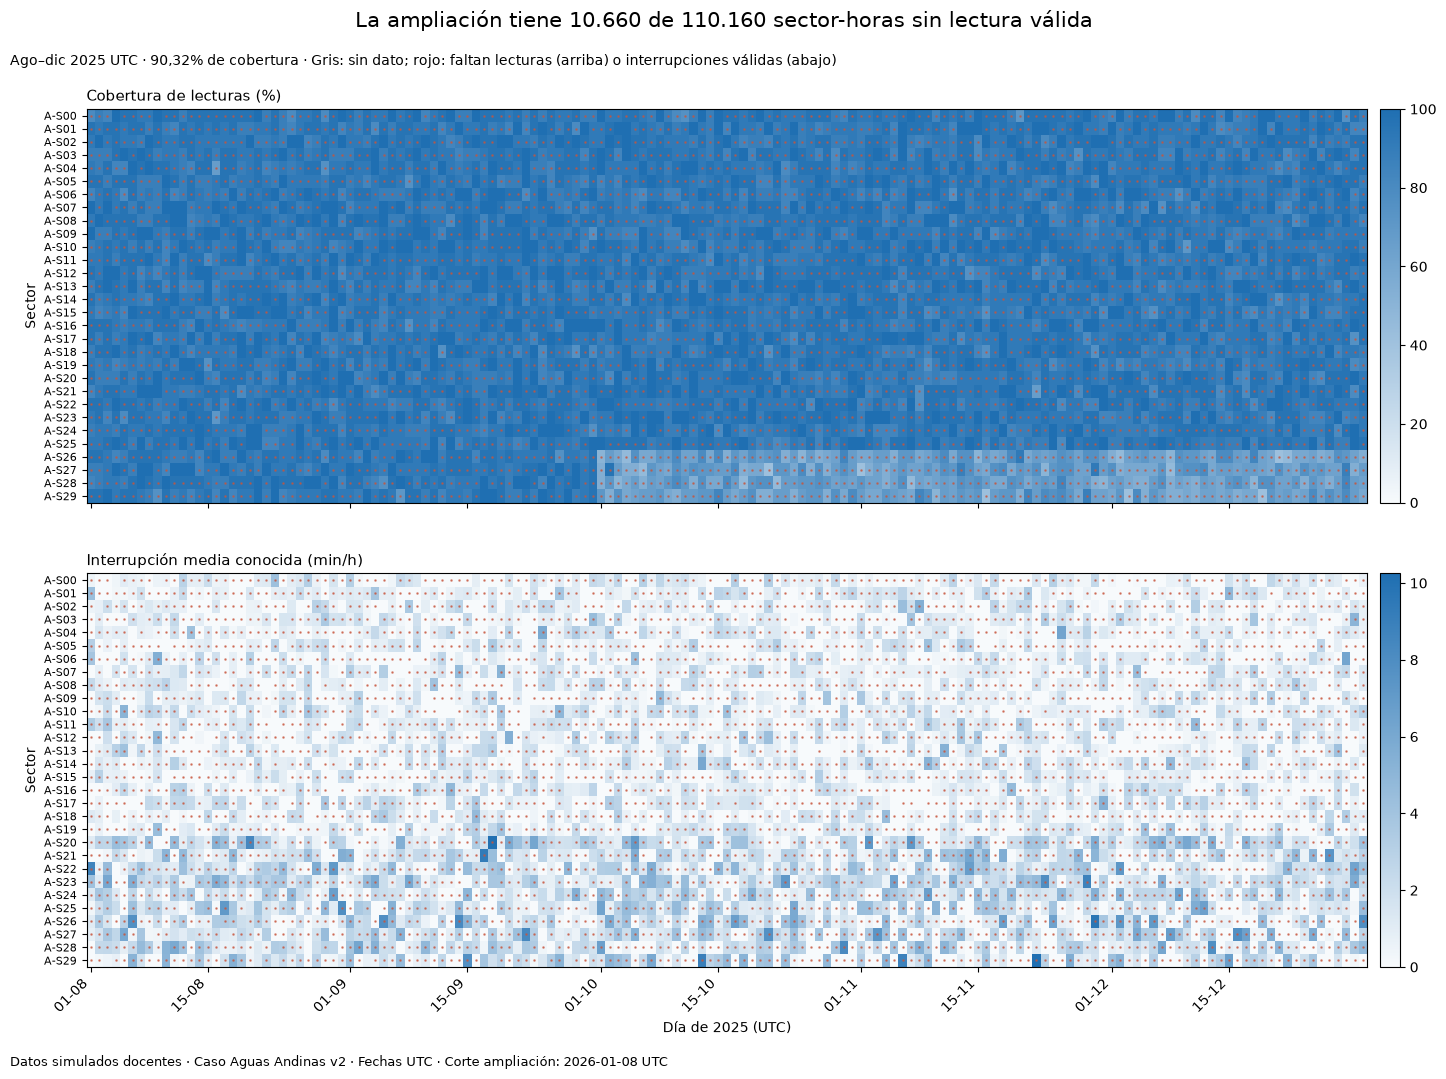

In [8]:
with plt.ioff():
    figuras = t3.generar_figuras(tablas)
for figura in figuras.values():
    plt.close(figura)  # Evitar que el backend inline muestre las otras figuras automáticamente.
display(figuras["cobertura_interrupciones"])
plt.close(figuras["cobertura_interrupciones"])

In [9]:
display(Markdown(f"""**Observación:** faltan {numero(estadisticas['horas_ausentes'])} de 110.160 sector-horas válidas ({numero(100 - estadisticas['cobertura_pct'], 2)}%) en agosto–diciembre. Hay {numero(estadisticas['dias_parciales'])} de {numero(estadisticas['dias_sector'])} sector-días con recepción parcial y {numero(estadisticas['dias_sin_lectura'])} sin lectura.

**Hipótesis:** puede existir una diferencia de captura o transmisión entre sectores; no está demostrada. **Acción:** acompañar las interrupciones con cobertura y revisar los segmentos con huecos. **Límite:** la media conocida no informa qué ocurrió en las horas faltantes; los datos son simulados."""))

**Observación:** faltan 10.660 de 110.160 sector-horas válidas (9,68%) en agosto–diciembre. Hay 3.941 de 4.590 sector-días con recepción parcial y 0 sin lectura.

**Hipótesis:** puede existir una diferencia de captura o transmisión entre sectores; no está demostrada. **Acción:** acompañar las interrupciones con cobertura y revisar los segmentos con huecos. **Límite:** la media conocida no informa qué ocurrió en las horas faltantes; los datos son simulados.

**Pregunta 2:** ¿qué sectores se pueden clasificar frente a la meta de continuidad considerando las horas desconocidas? Cada intervalo combina los escenarios 60/0; el punto observado utiliza solamente exposición conocida. El eje porcentual está ampliado para leer intervalos, sin representar barras ni áreas.

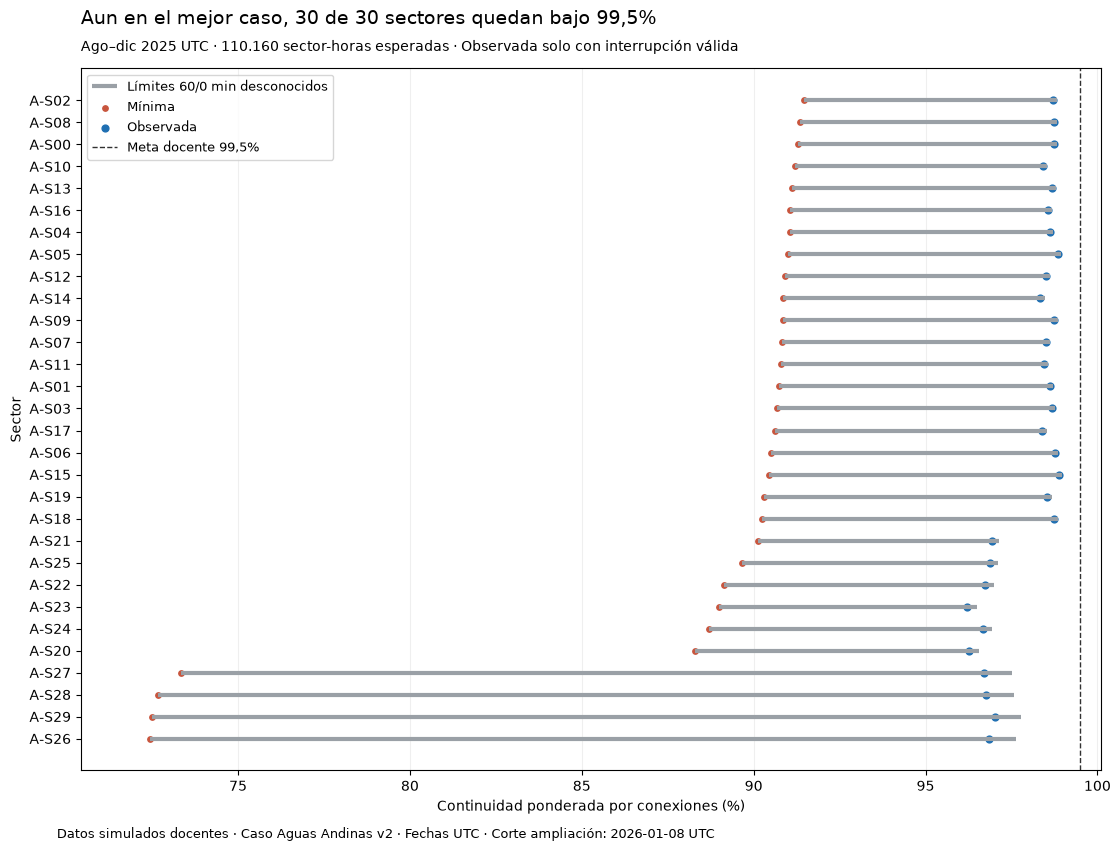

In [10]:
display(figuras["continuidad_limites"])
plt.close(figuras["continuidad_limites"])

In [11]:
display(Markdown(f"""**Observación:** en agosto–diciembre, el intervalo de {estadisticas['sectores_inciertos']} de 30 sectores cruza 99,5%; {estadisticas['sectores_bajo_meta']} quedan bajo la meta aun en el mejor caso y {estadisticas['sectores_cumplimiento']} cumplen aun en el peor.

**Hipótesis:** la amplitud proviene de exposición desconocida; no implica necesariamente interrupciones reales. **Acción:** llevar cobertura y ambos límites al ranking y recolectar evidencia donde la clasificación sea incierta. **Límite:** escenarios extremos no son estimaciones probabilísticas ni valores recuperados."""))

**Observación:** en agosto–diciembre, el intervalo de 0 de 30 sectores cruza 99,5%; 30 quedan bajo la meta aun en el mejor caso y 0 cumplen aun en el peor.

**Hipótesis:** la amplitud proviene de exposición desconocida; no implica necesariamente interrupciones reales. **Acción:** llevar cobertura y ambos límites al ranking y recolectar evidencia donde la clasificación sea incierta. **Límite:** escenarios extremos no son estimaciones probabilísticas ni valores recuperados.

**Pregunta 3:** ¿cómo se relacionan presión e interrupciones en los días observados, y qué cobertura respalda esa comparación? Cada punto es un sector-día. La mediana de presión y la interrupción media se calculan sobre **las mismas horas pareadas**. El color representa cobertura de lecturas, no certeza de la interrupción. No se introduce un umbral nuevo de presión baja.

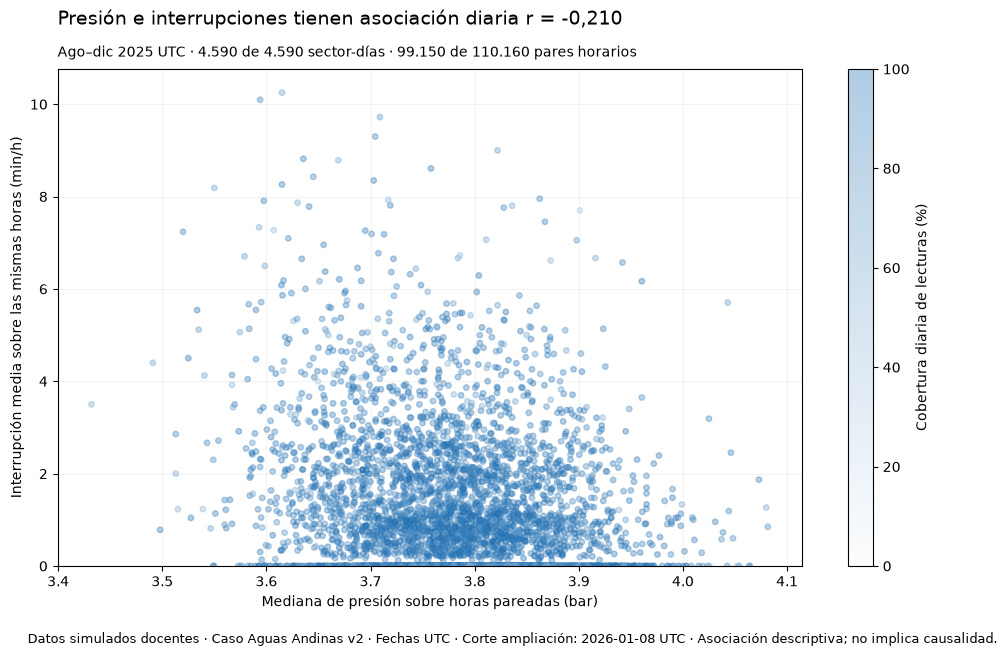

In [12]:
display(figuras["presion_interrupciones"])
plt.close(figuras["presion_interrupciones"])

In [13]:
display(Markdown(f"""**Observación:** hay pares válidos en {numero(estadisticas['dias_pareados'])} de {numero(estadisticas['dias_sector'])} sector-días, respaldados por {numero(estadisticas['horas_pareadas'])} de 110.160 horas esperadas; {numero(estadisticas['horas_excluidas_pares'])} horas no aportan un par. La correlación descriptiva diaria presión–interrupción es {numero(estadisticas['correlacion_diaria'], 3)} y presión–cobertura es {numero(estadisticas['correlacion_presion_cobertura'], 3)}.

**Hipótesis:** cualquier patrón podría depender de la operación o del proceso de medición; no se identifica una causa. **Acción:** contrastar los grupos con cobertura limitada antes de interpretar la asociación. **Límite:** agregación diaria y selección de horas conocidas; no permite conocer presión en los huecos, ni inferir causalidad o potabilidad."""))

**Observación:** hay pares válidos en 4.590 de 4.590 sector-días, respaldados por 99.150 de 110.160 horas esperadas; 11.010 horas no aportan un par. La correlación descriptiva diaria presión–interrupción es -0,210 y presión–cobertura es 0,030.

**Hipótesis:** cualquier patrón podría depender de la operación o del proceso de medición; no se identifica una causa. **Acción:** contrastar los grupos con cobertura limitada antes de interpretar la asociación. **Límite:** agregación diaria y selección de horas conocidas; no permite conocer presión en los huecos, ni inferir causalidad o potabilidad.

## 7. Validaciones numéricas y contrato para T5

Los siguientes casos se calculan también a mano: todas las horas conocidas; 80 de 100 sin interrupción; ninguna conocida; dos horas con conexiones 100/200 e interrupciones 60/0; y una lectura recibida con 90 minutos. Se verifica además que agregar una copia exacta no cambie la grilla.

Las comprobaciones del paquete contrastan T3 con T2, controlan semanas parciales, vigencias, denominadores y límites. No se usan datos inventados para producir indicadores ni un ranking real.

In [14]:
print(t3.probar_casos())
print(t3.validar_resultados(df, ctx, ev, grilla, tablas))
print(t3.probar_copia_adicional(df, ctx, ev, grilla))
display(tablas["por_sector"])
assert list(tablas["por_sector"].columns) == rq.COLUMNAS_CONTRATO["t3"]
assert tablas["por_sector"].horas_esperadas.eq(3672).all()
print("Contrato T3 listo: 30 sectores, agosto–diciembre UTC, columnas y porcentajes válidos.")

OK: completo, parcial, sin observaciones, pesos cambiantes e interrupción inválida.
OK: hashes, grilla, T2, exposiciones, semanas, vigencias y contrato del ranking.


OK: una copia adicional no cambia cobertura, pesos ni continuidad.


,sector_id,horas_esperadas,horas_observadas,cobertura_pct,continuidad_obs_pct,continuidad_min_pct,continuidad_max_pct
0,A-S00,3672,3406,92.755991,98.739151,91.289375,98.834281
1,A-S01,3672,3392,92.374728,98.611209,90.730182,98.722201
2,A-S02,3672,3412,92.919390,98.720023,91.454199,98.814230
3,A-S03,3672,3392,92.374728,98.671003,90.689978,98.778499
4,A-S04,3672,3399,92.565359,98.608177,91.058048,98.714744
5,A-S05,3672,3389,92.293028,98.862044,91.004232,98.952492
6,A-S06,3672,3376,91.938998,98.757152,90.509334,98.860950
7,A-S07,3672,3401,92.619826,98.489729,90.835610,98.607100
8,A-S08,3672,3416,93.028322,98.731308,91.337255,98.826321
9,A-S09,3672,3392,92.374728,98.749313,90.840245,98.849484


Contrato T3 listo: 30 sectores, agosto–diciembre UTC, columnas y porcentajes válidos.


## 8. Exportación y entrega de resultados

Esta celda regenera exclusivamente CSV y PNG `T3_` en `E1/salidas/`. No ejecuta el ranking ni escribe el PDF final.

T5 debe importar el módulo, integrar las celdas explicativas y usar `T3_por_sector.csv` junto a los productos oficiales de T2/T4. Las exposiciones detalladas quedan en `T3_continuidad_sector_ago_dic.csv`; las figuras utilizan el resumen diario exportado. Los hallazgos se documentan en `tareas/T3_cobertura_catalogos.md` y las decisiones en `decisiones.md`.

In [15]:
rutas = t3.exportar(tablas, figuras)
for ruta in rutas:
    print(ruta.relative_to(t3.E1))
comun.verificar_hashes()
print("Exportación completa; originales intactos.")

salidas/tablas/T3_cobertura_sector_semana.csv
salidas/tablas/T3_cobertura_sector_mes.csv
salidas/tablas/T3_cobertura_sector_hora.csv
salidas/tablas/T3_continuidad_sector_semana.csv
salidas/tablas/T3_por_sector.csv
salidas/tablas/T3_continuidad_sector_ago_dic.csv
salidas/tablas/T3_resumen_sector_dia.csv
salidas/tablas/T3_comparacion_lotes.csv
salidas/tablas/T3_uniones.csv
salidas/tablas/T3_comparacion_metas.csv
salidas/figuras/T3_cobertura_interrupciones.png
salidas/figuras/T3_continuidad_limites.png
salidas/figuras/T3_presion_interrupciones.png
Exportación completa; originales intactos.
